In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os
print(os.getcwd())
print(os.listdir())

/home/jovyan/bd-a1/notebook
['.ipynb_checkpoints', 'analysis.ipynb']


In [3]:


df = pd.read_csv("../data/dataset.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Number of rows and columns: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:

print("First 5 rows:")
display(df.head())

print("Dataset dimensions:")
print(df.shape)

print("Column names:")
print(df.columns)

print("Data types:")
print(df.dtypes)

print("Dataset information:")
df.info()

print("Descriptive statistics:")
display(df.describe(include="all"))


First 5 rows:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Dataset dimensions:
(5572, 2)
Column names:
Index(['label', 'message'], dtype='str')
Data types:
label      str
message    str
dtype: object
Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB
Descriptive statistics:


,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [5]:

# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Count duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Display duplicates
print("\nExamples of duplicate rows:")
display(df[df.duplicated()].head())


Missing values in each column:
label      0
message    0
dtype: int64

Number of duplicate rows:
403

Examples of duplicate rows:


,label,message
103,ham,As per your request 'Melle Melle (Oru Minnamin...
154,ham,As per your request 'Melle Melle (Oru Minnamin...
207,ham,"As I entered my cabin my PA said, '' Happy B'd..."
223,ham,"Sorry, I'll call later"
326,ham,No calls..messages..missed calls


In [6]:

# Make a copy so the original data remains unchanged
df_clean = df.copy()

# Remove rows with missing labels or messages
df_clean = df_clean.dropna(subset=["label", "message"])

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove accidental spaces around labels and messages
df_clean["label"] = df_clean["label"].str.strip()
df_clean["message"] = df_clean["message"].str.strip()

# Remove rows with empty labels or messages
df_clean = df_clean[
    (df_clean["label"] != "") &
    (df_clean["message"] != "")
]

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Remaining missing values:")
print(df_clean.isnull().sum())
print("Remaining duplicates:", df_clean.duplicated().sum())


Original shape: (5572, 2)
Cleaned shape: (5169, 2)
Remaining missing values:
label      0
message    0
dtype: int64
Remaining duplicates: 11


In [7]:

from pathlib import Path

output_dir = Path("../output")
output_dir.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(output_dir / "cleaned_data.csv", index=False)

print("Cleaned dataset saved to output/cleaned_data.csv")


Cleaned dataset saved to output/cleaned_data.csv


In [8]:

# 1. Select rows using loc (by index labels)
print("Using loc:")
display(df_clean.loc[0:4, ["label", "message"]])

# 2. Select rows using iloc (by row positions)
print("Using iloc:")
display(df_clean.iloc[0:5, :])

# 3. Select specific row positions using NumPy's r_
selected_rows = np.r_[0:3, 10:13]
display(df_clean.iloc[selected_rows])


Using loc:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Using iloc:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
10,ham,I'm gonna be home soon and i don't want to tal...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."
12,spam,URGENT! You have won a 1 week FREE membership ...


In [9]:

# Transformation 1: Convert labels into numbers
df_clean["label_number"] = df_clean["label"].map({
    "ham": 0,
    "spam": 1
})

# Transformation 2: Count characters in each SMS
df_clean["message_length"] = df_clean["message"].str.len()

# Transformation 3: Count words in each SMS
df_clean["word_count"] = df_clean["message"].str.split().str.len()

print("Transformed dataset:")
display(df_clean.head())

print("New columns:")
print(df_clean.columns.tolist())


Transformed dataset:


,label,message,label_number,message_length,word_count
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,20
1,ham,Ok lar... Joking wif u oni...,0,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,28
3,ham,U dun say so early hor... U c already then say...,0,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,13


New columns:
['label', 'message', 'label_number', 'message_length', 'word_count']


In [10]:

df_clean.to_csv("../output/cleaned_data.csv", index=False)

print("Updated cleaned dataset saved successfully!")


Updated cleaned dataset saved successfully!


In [11]:

# Calculate average message length for each label
average_length = df_clean.groupby("label")["message_length"].mean()

print("Average message length:")
print(average_length)

# Calculate average word count for each label
average_words = df_clean.groupby("label")["word_count"].mean()

print("\nAverage word count:")
print(average_words)


Average message length:
label
ham      70.869575
spam    137.656968
Name: message_length, dtype: float64

Average word count:
label
ham     14.239814
spam    23.739663
Name: word_count, dtype: float64


Figures folder is ready!


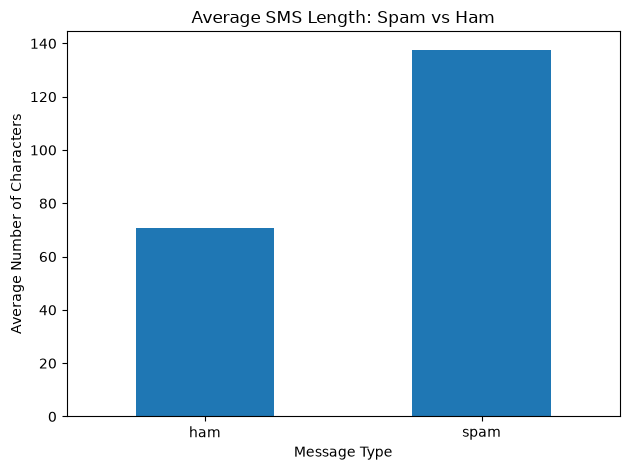

In [12]:

from pathlib import Path

Path("../output/figures").mkdir(parents=True, exist_ok=True)

print("Figures folder is ready!")

average_length.plot(kind="bar")


plt.title("Average SMS Length: Spam vs Ham")
plt.xlabel("Message Type")
plt.ylabel("Average Number of Characters")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../output/figures/average_message_length.png")
plt.show()


label
ham     4516
spam     653
Name: count, dtype: int64


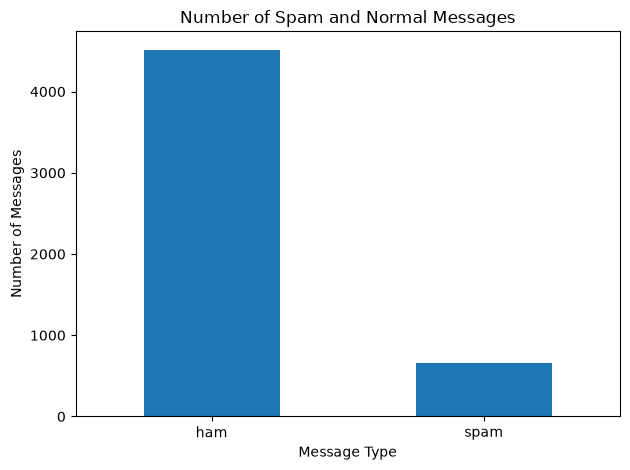

In [13]:

label_counts = df_clean["label"].value_counts()

print(label_counts)

label_counts.plot(kind="bar")
plt.title("Number of Spam and Normal Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../output/figures/message_class_distribution.png")
plt.show()


In [14]:

# 1. Number of characters
df_clean["message_length"] = df_clean["message"].str.len()

# 2. Number of words
df_clean["word_count"] = df_clean["message"].str.split().str.len()

# 3. Number of digits
df_clean["digit_count"] = df_clean["message"].str.count(r"\d")

# 4. Number of exclamation marks
df_clean["exclamation_count"] = df_clean["message"].str.count("!")

display(df_clean[[
    "label", "message", "message_length",
    "word_count", "digit_count", "exclamation_count"
]].head())




,label,message,message_length,word_count,digit_count,exclamation_count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20,0,0
1,ham,Ok lar... Joking wif u oni...,29,6,0,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,25,0
3,ham,U dun say so early hor... U c already then say...,49,11,0,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13,0,0


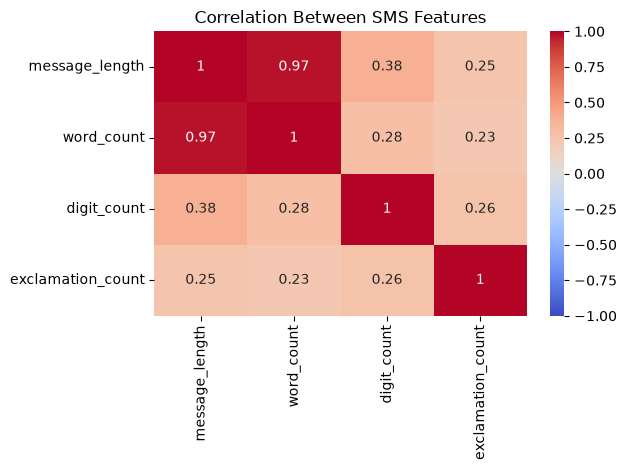

In [15]:

features = [
    "message_length",
    "word_count",
    "digit_count",
    "exclamation_count"
]

correlation = df_clean[features].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1)

plt.title("Correlation Between SMS Features")
plt.tight_layout()
plt.savefig("../output/figures/correlation_heatmap.png")
plt.show()


In [16]:

df_clean.to_csv("../output/cleaned_data.csv", index=False)

print("Updated dataset saved successfully!")


Updated dataset saved successfully!


In [17]:

# Random sample: select 20% of all messages
random_sample = df_clean.sample(frac=0.2, random_state=42)

# Stratified sample: select 20% while preserving spam/ham proportions
stratified_sample = (
    df_clean.groupby("label", group_keys=False)
    .sample(frac=0.2, random_state=42)
)

# Cluster sample: divide messages into 10 groups, then select 2 groups
df_cluster = df_clean.copy()
df_cluster["cluster"] = np.arange(len(df_cluster)) % 10

selected_clusters = [0, 1]
cluster_sample = df_cluster[
    df_cluster["cluster"].isin(selected_clusters)
]

print("Original dataset:", len(df_clean))
print("Random sample:", len(random_sample))
print("Stratified sample:", len(stratified_sample))
print("Cluster sample:", len(cluster_sample))


Original dataset: 5169
Random sample: 1034
Stratified sample: 1034
Cluster sample: 1034


In [18]:

samples = {
    "Original": df_clean,
    "Random": random_sample,
    "Stratified": stratified_sample,
    "Cluster": cluster_sample
}

for name, sample in samples.items():
    spam_percentage = (sample["label"] == "spam").mean() * 100
    ham_percentage = (sample["label"] == "ham").mean() * 100

    print(f"\n{name} sample")
    print(f"Spam: {spam_percentage:.2f}%")
    print(f"Ham:  {ham_percentage:.2f}%")



Original sample
Spam: 12.63%
Ham:  87.37%

Random sample
Spam: 13.54%
Ham:  86.46%

Stratified sample
Spam: 12.67%
Ham:  87.33%

Cluster sample
Spam: 11.12%
Ham:  88.88%


In [19]:

random_sample.to_csv("../output/random_sample.csv", index=False)
stratified_sample.to_csv("../output/stratified_sample.csv", index=False)
cluster_sample.to_csv("../output/cluster_sample.csv", index=False)

print("All three samples saved successfully!")


All three samples saved successfully!


In [20]:

from pathlib import Path

output_dir = Path("../output")

print("Files created in output:")

for file in sorted(output_dir.rglob("*")):
    if file.is_file():
        print(file)


Files created in output:
../output/bonus_model_comparison.csv
../output/cleaned_data.csv
../output/cluster_sample.csv
../output/cluster_summary.txt
../output/figures/average_message_length.png
../output/figures/confusion_matrix.png
../output/figures/correlation_heatmap.png
../output/figures/message_class_distribution.png
../output/model_metrics.txt
../output/random_sample.csv
../output/stratified_sample.csv


In [21]:
#Machine Learning

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['message'], df['label'],
    test_size=0.2, random_state=42, stratify=df['label']
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])

Train size: 4457
Test size: 1115


In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=3000, stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF shape (train):", X_train_tfidf.shape)

TF-IDF shape (train): (4457, 3000)


In [24]:
from sklearn.naive_bayes import MultinomialNB

clf = MultinomialNB()
clf.fit(X_train_tfidf, y_train)
y_pred = clf.predict(X_test_tfidf)

print("Model trained successfully!")

Model trained successfully!


In [25]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label='spam')
rec = recall_score(y_test, y_pred, pos_label='spam')
f1 = f1_score(y_test, y_pred, pos_label='spam')

print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-score: {f1:.4f}")
print(classification_report(y_test, y_pred))

Accuracy: 0.9749
Precision: 1.0000
Recall: 0.8121
F1-score: 0.8963
              precision    recall  f1-score   support

         ham       0.97      1.00      0.99       966
        spam       1.00      0.81      0.90       149

    accuracy                           0.97      1115
   macro avg       0.99      0.91      0.94      1115
weighted avg       0.98      0.97      0.97      1115



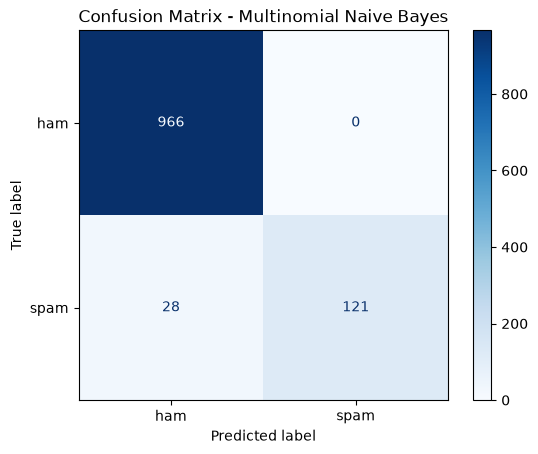

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.savefig('../output/figures/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_all_tfidf = tfidf.transform(df['message'])

scores = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_all_tfidf)
    score = silhouette_score(X_all_tfidf, labels, sample_size=1000, random_state=42)
    scores[k] = score
    print(f"k={k}: silhouette={score:.4f}")

k=2: silhouette=0.0087
k=3: silhouette=0.0092
k=4: silhouette=0.0118
k=5: silhouette=0.0125
k=6: silhouette=0.0131


In [28]:
best_k = 2
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_all_tfidf)
df['cluster'] = cluster_labels

final_silhouette = silhouette_score(X_all_tfidf, cluster_labels, sample_size=1000, random_state=42)
cluster_sizes = df['cluster'].value_counts().sort_index()
print(cluster_sizes)
print(f"Silhouette score: {final_silhouette:.4f}")

cluster
0    5349
1     223
Name: count, dtype: int64
Silhouette score: 0.0087


In [29]:
terms = tfidf.get_feature_names_out()
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

top_terms_per_cluster = {}
for i in range(best_k):
    top_terms = [terms[ind] for ind in order_centroids[i, :10]]
    top_terms_per_cluster[i] = top_terms
    print(f"Cluster {i}: {', '.join(top_terms)}")

Cluster 0: ok, just, ll, ur, come, good, know, like, time, got
Cluster 1: gt, lt, decimal, like, min, ll, minutes, come, got, rs


In [30]:
comparison = pd.crosstab(df['cluster'], df['label'])
print(comparison)

label     ham  spam
cluster            
0        4602   747
1         223     0


In [31]:
with open('../output/model_metrics.txt', 'w') as f:
    f.write("Model: Multinomial Naive Bayes\n")
    f.write(f"Accuracy: {acc:.4f}\n")
    f.write(f"Precision: {prec:.4f}\n")
    f.write(f"Recall: {rec:.4f}\n")
    f.write(f"F1-score: {f1:.4f}\n\n")
    f.write("Classification Report:\n")
    f.write(classification_report(y_test, y_pred))

with open('../output/cluster_summary.txt', 'w') as f:
    f.write(f"Number of clusters (k): {best_k}\n")
    f.write(f"Silhouette score: {final_silhouette:.4f}\n\n")
    f.write("Cluster sizes:\n")
    f.write(str(cluster_sizes) + "\n\n")
    f.write("Top terms per cluster:\n")
    for i, t in top_terms_per_cluster.items():
        f.write(f"Cluster {i}: {', '.join(t)}\n")
    f.write("\nCluster vs actual label:\n")
    f.write(str(comparison))

print("Files saved successfully!")

Files saved successfully!


In [32]:
##Bonus

In [33]:
##Compare Compare Naive Bayes and Logistic Regression

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_tfidf, y_train)
lr_pred = lr.predict(X_test_tfidf)

predictions = {
    "Naive Bayes": y_pred,
    "Logistic Regression": lr_pred
}

results = []

for name, prediction in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Spam precision": precision_score(
            y_test, prediction, pos_label="spam", zero_division=0
        ),
        "Spam recall": recall_score(
            y_test, prediction, pos_label="spam", zero_division=0
        ),
        "Spam F1": f1_score(
            y_test, prediction, pos_label="spam", zero_division=0
        )
    })

bonus_results = pd.DataFrame(results).set_index("Model")
display(bonus_results.round(4))

,Accuracy,Spam precision,Spam recall,Spam F1
Model,,,,
Naive Bayes,0.9749,1.0,0.8121,0.8963
Logistic Regression,0.9722,1.0,0.7919,0.8839


In [35]:
## Interpret and save

In [37]:
from pathlib import Path

output_dir = Path("../output")

nb_f1 = bonus_results.loc["Naive Bayes", "Spam F1"]
lr_f1 = bonus_results.loc["Logistic Regression", "Spam F1"]

if lr_f1 > nb_f1:
    conclusion = "Logistic Regression has the higher spam F1-score."
elif nb_f1 > lr_f1:
    conclusion = "Naive Bayes has the higher spam F1-score."
else:
    conclusion = "Both classifiers have the same spam F1-score."

explanation = (
    "Both classifiers use the same training/test split and TF-IDF features. "
    f"Naive Bayes has a spam F1-score of {nb_f1:.4f}, while "
    f"Logistic Regression has {lr_f1:.4f}. "
    f"{conclusion} "
    "F1 balances precision and recall, which is useful for imbalanced classes. "
    "These results are from one fixed split, and the test set was not "
    "used for tuning."
)

print(explanation)

bonus_results.to_csv(output_dir / "bonus_model_comparison.csv")

report = (
    "\n\nBonus: Classifier comparison\n"
    + bonus_results.to_string()
    + "\n\n"
    + explanation
)

metrics_file = output_dir / "model_metrics.txt"
original_report = metrics_file.read_text(encoding="utf-8")
original_report = original_report.split("\n\nBonus: Classifier comparison")[0]
metrics_file.write_text(original_report + report, encoding="utf-8");

Both classifiers use the same training/test split and TF-IDF features. Naive Bayes has a spam F1-score of 0.8963, while Logistic Regression has 0.8839. Naive Bayes has the higher spam F1-score. F1 balances precision and recall, which is useful for imbalanced classes. These results are from one fixed split, and the test set was not used for tuning.
